# ============================================================
# ODyanDemo4.0
## Computational Opinion Dynamics Architecture (CODA)

### Reference Implementation

This notebook implements the Computational Opinion Dynamics Architecture (CODA) developed for Paper 1

**A Modular Computational Architecture for Continuous Opinion Dynamics**

**A Novel Computational Framework for Centrality-Weighted Influence in Continuous Opinion Dynamics**

Implemented interaction mechanisms

* Deffuant–Weisbuch (DW)
* Hegselmann–Krause (HK)
* Centrality-Weighted Interaction Model (CWIM)

Current Version
> ODyanDemo4.0

Features

* Modular architecture
* Reproducible experiments
* Multiple network generators
* Multiple opinion initializers
* Publication-quality figures
* Sensitivity analysis
* Exportable experimental results

In [ ]:
# ============================================================
# SECTION 1 : IMPORTS
# ============================================================

import random
import warnings
from collections import defaultdict
from itertools import product

import numpy as np
import pandas as pd

import networkx as nx

import matplotlib.pyplot as plt

from scipy.stats import beta

from IPython.display import display

warnings.filterwarnings("ignore")

In [ ]:
# ============================================================
# REPRODUCIBILITY
# ============================================================

GLOBAL_RANDOM_SEED = 42

random.seed(GLOBAL_RANDOM_SEED)
np.random.seed(GLOBAL_RANDOM_SEED)

In [ ]:
# ============================================================
# PLOTS
# ============================================================

plt.rcParams.update({

    "figure.figsize": (7,5),

    "figure.dpi": 120,

    "axes.grid": True,

    "grid.alpha": 0.30,

    "axes.spines.top": False,

    "axes.spines.right": False,

    "axes.labelsize": 11,

    "axes.titlesize": 12,

    "xtick.labelsize": 10,

    "ytick.labelsize": 10,

    "legend.fontsize": 10,

    "font.family": "serif",

    "font.serif": ["Times New Roman"],

    "savefig.bbox": "tight"

})

In [ ]:
# ============================================================
# GLOBAL PARAMETERS
# ============================================================

# ------------------------------------------------------------
# Network
# ------------------------------------------------------------

N_AGENTS = 200

NETWORK_SEED = 42

# ------------------------------------------------------------
# Simulation
# ------------------------------------------------------------

MAX_ITER = 500

MAX_INTERACTIONS = 100000

CONVERGENCE_TOL = 1e-6

CLUSTER_GAP = 0.02

# ------------------------------------------------------------
# DW Parameters
# ------------------------------------------------------------

DW_EPS = 0.20

DW_MU = 0.25

# ------------------------------------------------------------
# HK Parameters
# ------------------------------------------------------------

HK_EPS = 0.20

# ------------------------------------------------------------
# CWIM Parameters
# ------------------------------------------------------------

CWIM_ALPHA = 0.25

CWIM_GAMMA = 1.0

CWIM_SIGMA = 0.15

CWIM_ETA = 2.0

CWIM_CENTRALITY = "degree"

# ------------------------------------------------------------
# Sensitivity Analysis
# ------------------------------------------------------------

SIGMA_VALUES = [0.02, 0.05, 0.10, 0.20, 0.40]

GAMMA_VALUES = [0.5, 1.0, 2.0]

ALPHA_VALUES = [0.05, 0.10, 0.20, 0.30]

PARAMETER_GRID = list(

    product(

        SIGMA_VALUES,

        GAMMA_VALUES,

        ALPHA_VALUES

    )

)

# ------------------------------------------------------------
# Replications
# ------------------------------------------------------------

N_REPLICATIONS = 20

# ------------------------------------------------------------
# Available Network Models
# ------------------------------------------------------------

NETWORK_TYPES = [

    "ER",

    "BA",

    "WS",

    "SBM"

]

In [ ]:
# ============================================================
# EXPERIMENT CONFIGURATION
# ============================================================

CONFIG = {

    "agents": N_AGENTS,

    "network_seed": NETWORK_SEED,

    "global_seed": GLOBAL_RANDOM_SEED,

    "replications": N_REPLICATIONS,

    "max_iter": MAX_ITER,

    "max_interactions": MAX_INTERACTIONS,

    "tolerance": CONVERGENCE_TOL,

    "cluster_gap": CLUSTER_GAP,

    "dw_eps": DW_EPS,

    "dw_mu": DW_MU,

    "hk_eps": HK_EPS,

    "cwim_alpha": CWIM_ALPHA,

    "cwim_gamma": CWIM_GAMMA,

    "cwim_sigma": CWIM_SIGMA,

    "cwim_eta": CWIM_ETA,

    "cwim_centrality": CWIM_CENTRALITY

}

print("===================================================")
print("ODyanDemo4.0 Successfully Initialized")
print("===================================================")

for k, v in CONFIG.items():
    print(f"{k:25s}: {v}")

ODyanDemo3.0 Successfully Initialized
agents                   : 200
network_seed             : 42
global_seed              : 42
replications             : 20
max_iter                 : 500
max_interactions         : 100000
tolerance                : 1e-06
cluster_gap              : 0.02
dw_eps                   : 0.2
dw_mu                    : 0.25
hk_eps                   : 0.2
cwim_alpha               : 0.25
cwim_gamma               : 1.0
cwim_sigma               : 0.15
cwim_eta                 : 2.0
cwim_centrality          : degree


In [ ]:
# ============================================================
# VERSION INFORMATION
# ============================================================

print("===================================================")
print("CODA Reference Implementation")
print("===================================================")

print("Notebook Version : ODyanDemo4.0")
print("Architecture     : CODA")
print("Interaction Models:")
print("   • DW")
print("   • HK")
print("   • CWIM")
print("Agents           :", N_AGENTS)
print("Random Seed      :", GLOBAL_RANDOM_SEED)
print("===================================================")

CODA Reference Implementation
Notebook Version : ODyanDemo3.0
Architecture     : CODA
Interaction Models:
   • DW
   • HK
   • CWIM
Agents           : 200
Random Seed      : 42


# ============================================================
# SECTION 2 : UTILITY FUNCTIONS
# ============================================================

This section contains reusable utility functions used throughout CODA.

Modules

1. Cluster Detection
2. Polarization Metrics
3. Consensus Detection
4. Summary Statistics
5. Simulation Reporting
6. Plot Utilities

In [ ]:
# ============================================================
# CLUSTER DETECTION
# ============================================================

def identify_clusters(opinions, gap_threshold=CLUSTER_GAP):
    """
    Identify opinion clusters based on sorted opinion gaps.

    Parameters
    ----------
    opinions : array-like

    gap_threshold : float

    Returns
    -------
    clusters : list
        List of opinion clusters.
    """

    opinions = np.sort(np.asarray(opinions))

    if len(opinions) == 0:
        return []

    clusters = [[opinions[0]]]

    for value in opinions[1:]:

        if value - clusters[-1][-1] <= gap_threshold:

            clusters[-1].append(value)

        else:

            clusters.append([value])

    return clusters


def cluster_count_from_opinions(
    opinions,
    gap_threshold=CLUSTER_GAP,
):
    """
    Return number of opinion clusters.
    """

    return len(
        identify_clusters(
            opinions,
            gap_threshold,
        )
    )


def cluster_sizes(
    opinions,
    gap_threshold=CLUSTER_GAP,
):
    """
    Return size of each cluster.
    """

    return [

        len(c)

        for c in identify_clusters(

            opinions,

            gap_threshold

        )

    ]

In [ ]:
# ============================================================
# POLARIZATION METRICS
# ============================================================

def opinion_variance(opinions):
    """
    Opinion variance.
    """
    return np.var(opinions)


def opinion_std(opinions):
    """
    Opinion standard deviation.
    """
    return np.std(opinions)


def polarization_index(opinions):
    """
    Polarization index.

    Current implementation:
    Mean squared deviation from mean opinion.
    """

    opinions = np.asarray(opinions)

    mean_opinion = np.mean(opinions)

    return np.mean(
        (opinions - mean_opinion) ** 2
    )


# ============================================================
# CONSENSUS
# ============================================================

def consensus_reached(
    opinions,
    gap_threshold=CLUSTER_GAP,
):
    """
    Returns True if a single cluster exists.
    """

    return (

        cluster_count_from_opinions(

            opinions,

            gap_threshold

        )

        == 1

    )

In [ ]:
# ============================================================
# SUMMARY STATISTICS
# ============================================================

def summary_statistics(values):
    """
    Compute descriptive statistics.

    Returns
    -------
    dict
    """

    values = np.asarray(values)

    return {

        "mean": np.mean(values),

        "std": np.std(values),

        "median": np.median(values),

        "min": np.min(values),

        "max": np.max(values),

        "q1": np.percentile(values,25),

        "q3": np.percentile(values,75),

        "iqr":
            np.percentile(values,75)
            -
            np.percentile(values,25)

    }


def experiment_summary(opinions):

    return {

        "mean":
            np.mean(opinions),

        "std":
            opinion_std(opinions),

        "variance":
            opinion_variance(opinions),

        "polarization":
            polarization_index(opinions),

        "clusters":
            cluster_count_from_opinions(opinions),

        "consensus":
            consensus_reached(opinions)

    }

In [ ]:
# ============================================================
# SIMULATION REPORT
# ============================================================

def print_simulation_report(

    model,

    opinions,

    iterations,

):

    report = experiment_summary(opinions)

    print("="*55)

    print(f"Model           : {model}")

    print(f"Iterations      : {iterations}")

    print(f"Consensus       : {report['consensus']}")

    print(f"Clusters        : {report['clusters']}")

    print(f"Mean Opinion    : {report['mean']:.4f}")

    print(f"Std Opinion     : {report['std']:.4f}")

    print(f"Variance        : {report['variance']:.4f}")

    print(f"Polarization    : {report['polarization']:.4f}")

    print("="*55)

In [ ]:
# ============================================================
# PLOT UTILITIES
# ============================================================

def plot_opinion_distribution(

    opinions,

    title="Opinion Distribution",

    bins=20,

):

    plt.figure(figsize=(6,4))

    plt.hist(

        opinions,

        bins=bins,

        edgecolor="black",

        alpha=0.7

    )

    plt.xlabel("Opinion")

    plt.ylabel("Frequency")

    plt.title(title)

    plt.tight_layout()

    plt.show()


def plot_metric(

    values,

    ylabel,

    title,

):

    plt.figure(figsize=(6,4))

    plt.plot(

        values,

        linewidth=2

    )

    plt.xlabel("Iteration")

    plt.ylabel(ylabel)

    plt.title(title)

    plt.tight_layout()

    plt.show()


def plot_clusters(cluster_history):

    plot_metric(

        cluster_history,

        ylabel="Clusters",

        title="Cluster Evolution"

    )


def plot_polarization(pol_history):

    plot_metric(

        pol_history,

        ylabel="Polarization",

        title="Polarization Evolution"

    )

In [ ]:
# ============================================================
# VERIFY UTILITIES
# ============================================================

print("Utility functions loaded successfully.")

print("Available modules")

print("-------------------------------")

print("✓ Cluster Detection")

print("✓ Polarization Metrics")

print("✓ Consensus Detection")

print("✓ Summary Statistics")

print("✓ Simulation Reporting")

print("✓ Plot Utilities")

Utility functions loaded successfully.
Available modules
-------------------------------
✓ Cluster Detection
✓ Polarization Metrics
✓ Consensus Detection
✓ Summary Statistics
✓ Simulation Reporting
✓ Plot Utilities


# ============================================================
# SECTION 3 : OPINION INITIALIZATION
# ============================================================

This module generates the initial opinion distribution used by
all opinion dynamics models.

Supported initialization methods

1. Uniform Distribution
2. Normal Distribution
3. Beta Distribution
4. Synthetic Cluster Generator
5. ESS-based Empirical Initialization (yet to implement)

All generators return a dictionary

    {node : opinion}

where opinions are normalized to [0,1].

In [ ]:
# ============================================================
# UNIFORM INITIALIZATION
# ============================================================

def generate_uniform_opinions(
    G,
    low=0.0,
    high=1.0,
):
    """
    Generate uniformly distributed opinions.

    Parameters
    ----------
    G : networkx graph

    low : float

    high : float

    Returns
    -------
    dict
    """

    opinions = np.random.uniform(

        low,

        high,

        len(G.nodes())

    )

    return {

        node: float(op)

        for node, op in zip(

            G.nodes(),

            opinions

        )

    }

In [ ]:
# ============================================================
# NORMAL INITIALIZATION
# ============================================================

def generate_normal_opinions(

    G,

    mean=0.5,

    std=0.15,

):

    """
    Generate normally distributed opinions.

    Values outside [0,1]
    are clipped.
    """

    opinions = np.random.normal(

        mean,

        std,

        len(G.nodes())

    )

    opinions = np.clip(

        opinions,

        0,

        1

    )

    return {

        node: float(op)

        for node, op in zip(

            G.nodes(),

            opinions

        )

    }

In [ ]:
# ============================================================
# BETA INITIALIZATION
# ============================================================

def generate_beta_opinions(

    G,

    a=2,

    b=2,

):

    """
    Generate Beta distributed opinions.

    Useful for skewed
    empirical distributions.
    """

    opinions = np.random.beta(

        a,

        b,

        len(G.nodes())

    )

    return {

        node: float(op)

        for node, op in zip(

            G.nodes(),

            opinions

        )

    }

In [ ]:
# ============================================================
# SYNTHETIC CLUSTER GENERATOR
# ============================================================

def generate_clustered_opinions(

    G,

    cluster_means=[0.20,0.50,0.80],

    cluster_std=0.03,

    cluster_sizes=None,

):

    """
    Generate clustered opinion distributions.

    Parameters
    ----------
    cluster_means

    cluster_std

    cluster_sizes

    Returns
    -------
    dict
    """

    n = len(G.nodes())

    if cluster_sizes is None:

        base = n // len(cluster_means)

        cluster_sizes = [

            base

        ] * len(cluster_means)

        cluster_sizes[-1] += (

            n - sum(cluster_sizes)

        )

    opinions = []

    for mean, size in zip(

        cluster_means,

        cluster_sizes

    ):

        block = np.random.normal(

            mean,

            cluster_std,

            size

        )

        opinions.extend(block)

    opinions = np.clip(

        opinions,

        0,

        1

    )

    np.random.shuffle(opinions)

    return {

        node: float(op)

        for node, op in zip(

            G.nodes(),

            opinions

        )

    }

In [ ]:
# ============================================================
# ESS INITIALIZATION
# ============================================================

def generate_ESS_opinions(

    G,

    empirical_values,

    normalize=True,

):

    """
    Generate opinions from
    empirical survey data.

    Parameters
    ----------
    empirical_values

        Example:

        ESS Climate Change

        responses

        1–5

    normalize

    Returns
    -------
    dict
    """

    values = np.asarray(

        empirical_values,

        dtype=float

    )

    if normalize:

        values = (

            values -

            values.min()

        ) / (

            values.max()

            -

            values.min()

        )

    sampled = np.random.choice(

        values,

        size=len(G.nodes()),

        replace=True

    )

    return {

        node: float(op)

        for node, op in zip(

            G.nodes(),

            sampled

        )

    }

In [ ]:
# ============================================================
# MASTER INITIALIZATION FUNCTION
# ============================================================

def initialize_opinions(

    G,

    method="uniform",

    **kwargs

):

    """
    Master interface for opinion initialization.

    Methods

    uniform

    normal

    beta

    clustered

    ess
    """

    method = method.lower()

    if method == "uniform":

        return generate_uniform_opinions(

            G,

            **kwargs

        )

    elif method == "normal":

        return generate_normal_opinions(

            G,

            **kwargs

        )

    elif method == "beta":

        return generate_beta_opinions(

            G,

            **kwargs

        )

    elif method == "clustered":

        return generate_clustered_opinions(

            G,

            **kwargs

        )

    elif method == "ess":

        return generate_ESS_opinions(

            G,

            **kwargs

        )

    else:

        raise ValueError(

            "Unknown initialization method."

        )

In [ ]:
# ============================================================
# VISUALIZE INITIAL OPINIONS
# ============================================================

def plot_initial_distribution(

    opinions,

    title="Initial Opinion Distribution",

):

    plt.figure(figsize=(6,4))

    plt.hist(

        list(opinions.values()),

        bins=20,

        edgecolor="black",

        alpha=0.75

    )

    plt.xlabel("Opinion")

    plt.ylabel("Frequency")

    plt.title(title)

    plt.tight_layout()

    plt.show()

In [ ]:
# ============================================================
# VERIFY INITIALIZATION MODULE
# ============================================================

G = nx.path_graph(200)

methods = [

    "uniform",

    "normal",

    "beta",

    "clustered"

]

for method in methods:

    opinions = initialize_opinions(

        G,

        method=method

    )

    print(

        f"{method:12s}",

        "Mean =",

        round(

            np.mean(

                list(opinions.values())

            ),

            3

        )

    )

uniform      Mean = 0.484
normal       Mean = 0.51
beta         Mean = 0.501
clustered    Mean = 0.503


# ============================================================
# SECTION 4 : NETWORK GENERATION
# ============================================================

This module implements the network generation layer of CODA.

Supported network models

1. Erdős–Rényi (ER)
2. Barabási–Albert (BA)
3. Watts–Strogatz (WS)
4. Stochastic Block Model (SBM)

Each generator returns a connected NetworkX graph.

The master function `build_networks()` constructs the complete
benchmark collection used throughout the experiments.

In [ ]:
# ============================================================
# CONNECTIVITY HELPER
# ============================================================

def largest_connected_component(G):
    """
    Return the largest connected component.

    Parameters
    ----------
    G : networkx.Graph

    Returns
    -------
    networkx.Graph
    """

    if nx.is_connected(G):
        return G.copy()

    largest = max(
        nx.connected_components(G),
        key=len
    )

    return G.subgraph(largest).copy()

In [ ]:
# ============================================================
# ERDOS-RENYI NETWORK
# ============================================================

def generate_ER_network(

    n=N_AGENTS,

    p=0.02,

    seed=NETWORK_SEED

):
    """
    Generate connected
    Erdős–Rényi random graph.
    """

    G = nx.erdos_renyi_graph(

        n=n,

        p=p,

        seed=seed

    )

    return largest_connected_component(G)

In [ ]:
# ============================================================
# BARABASI-ALBERT NETWORK
# ============================================================

def generate_BA_network(

    n=N_AGENTS,

    m=3,

    seed=NETWORK_SEED

):
    """
    Generate Barabási–Albert
    scale-free network.
    """

    return nx.barabasi_albert_graph(

        n=n,

        m=m,

        seed=seed

    )

In [ ]:
# ============================================================
# WATTS-STROGATZ NETWORK
# ============================================================

def generate_WS_network(

    n=N_AGENTS,

    k=6,

    beta=0.10,

    seed=NETWORK_SEED

):
    """
    Generate Watts-Strogatz
    small-world network.
    """

    G = nx.watts_strogatz_graph(

        n=n,

        k=k,

        p=beta,

        seed=seed

    )

    return largest_connected_component(G)

In [ ]:
# ============================================================
# STOCHASTIC BLOCK MODEL
# ============================================================

def generate_SBM_network(

    n=N_AGENTS,

    blocks=10,

    p_intra=0.35,

    p_inter=0.01,

    seed=NETWORK_SEED

):
    """
    Generate stochastic
    block model network.
    """

    block_size = n // blocks

    sizes = [block_size] * blocks

    sizes[-1] += n - sum(sizes)

    probs = [

        [

            p_intra if i == j else p_inter

            for j in range(blocks)

        ]

        for i in range(blocks)

    ]

    G = nx.stochastic_block_model(

        sizes,

        probs,

        seed=seed

    )

    return largest_connected_component(G)

In [ ]:
# ============================================================
# BUILD BENCHMARK NETWORKS
# ============================================================

def build_networks(

    n=N_AGENTS,

    seed=NETWORK_SEED,

):
    """
    Construct the benchmark
    collection of networks
    used throughout CODA.
    """

    return {

        "ER":

            generate_ER_network(

                n=n,

                p=0.02,

                seed=seed

            ),

        "BA":

            generate_BA_network(

                n=n,

                m=3,

                seed=seed

            ),

        "WS":

            generate_WS_network(

                n=n,

                k=6,

                beta=0.10,

                seed=seed

            ),

        "SBM":

            generate_SBM_network(

                n=n,

                blocks=10,

                p_intra=0.35,

                p_inter=0.01,

                seed=seed

            )

    }

In [ ]:
# ============================================================
# NETWORK SUMMARY
# ============================================================

def network_summary(G):

    return {

        "Nodes":

            G.number_of_nodes(),

        "Edges":

            G.number_of_edges(),

        "Density":

            nx.density(G),

        "Average Degree":

            np.mean(

                [d for _, d in G.degree()]

            ),

        "Average Clustering":

            nx.average_clustering(G),

        "Connected":

            nx.is_connected(G)

    }


def print_network_summary(networks):

    print("="*72)

    print("Benchmark Networks")

    print("="*72)

    for name, G in networks.items():

        s = network_summary(G)

        print(

            f"{name:4s}"

            f" Nodes={s['Nodes']:3d}"

            f" Edges={s['Edges']:4d}"

            f" Density={s['Density']:.4f}"

            f" AvgDeg={s['Average Degree']:.2f}"

            f" Clustering={s['Average Clustering']:.3f}"

        )

In [ ]:
# ============================================================
# VISUALIZE NETWORKS
# ============================================================

def plot_networks(networks):

    fig, axes = plt.subplots(

        2,

        2,

        figsize=(10,10)

    )

    axes = axes.flatten()

    for ax, (name, G) in zip(

        axes,

        networks.items()

    ):

        pos = nx.spring_layout(

            G,

            seed=NETWORK_SEED

        )

        nx.draw_networkx(

            G,

            pos=pos,

            node_size=10,

            with_labels=False,

            edge_color="gray",

            ax=ax

        )

        ax.set_title(name)

        ax.set_axis_off()

    plt.tight_layout()

    plt.show()

Benchmark Networks
ER   Nodes=195 Edges= 375 Density=0.0198 AvgDeg=3.85 Clustering=0.017
BA   Nodes=200 Edges= 591 Density=0.0297 AvgDeg=5.91 Clustering=0.102
WS   Nodes=200 Edges= 600 Density=0.0302 AvgDeg=6.00 Clustering=0.438
SBM  Nodes=200 Edges= 861 Density=0.0433 AvgDeg=8.61 Clustering=0.216


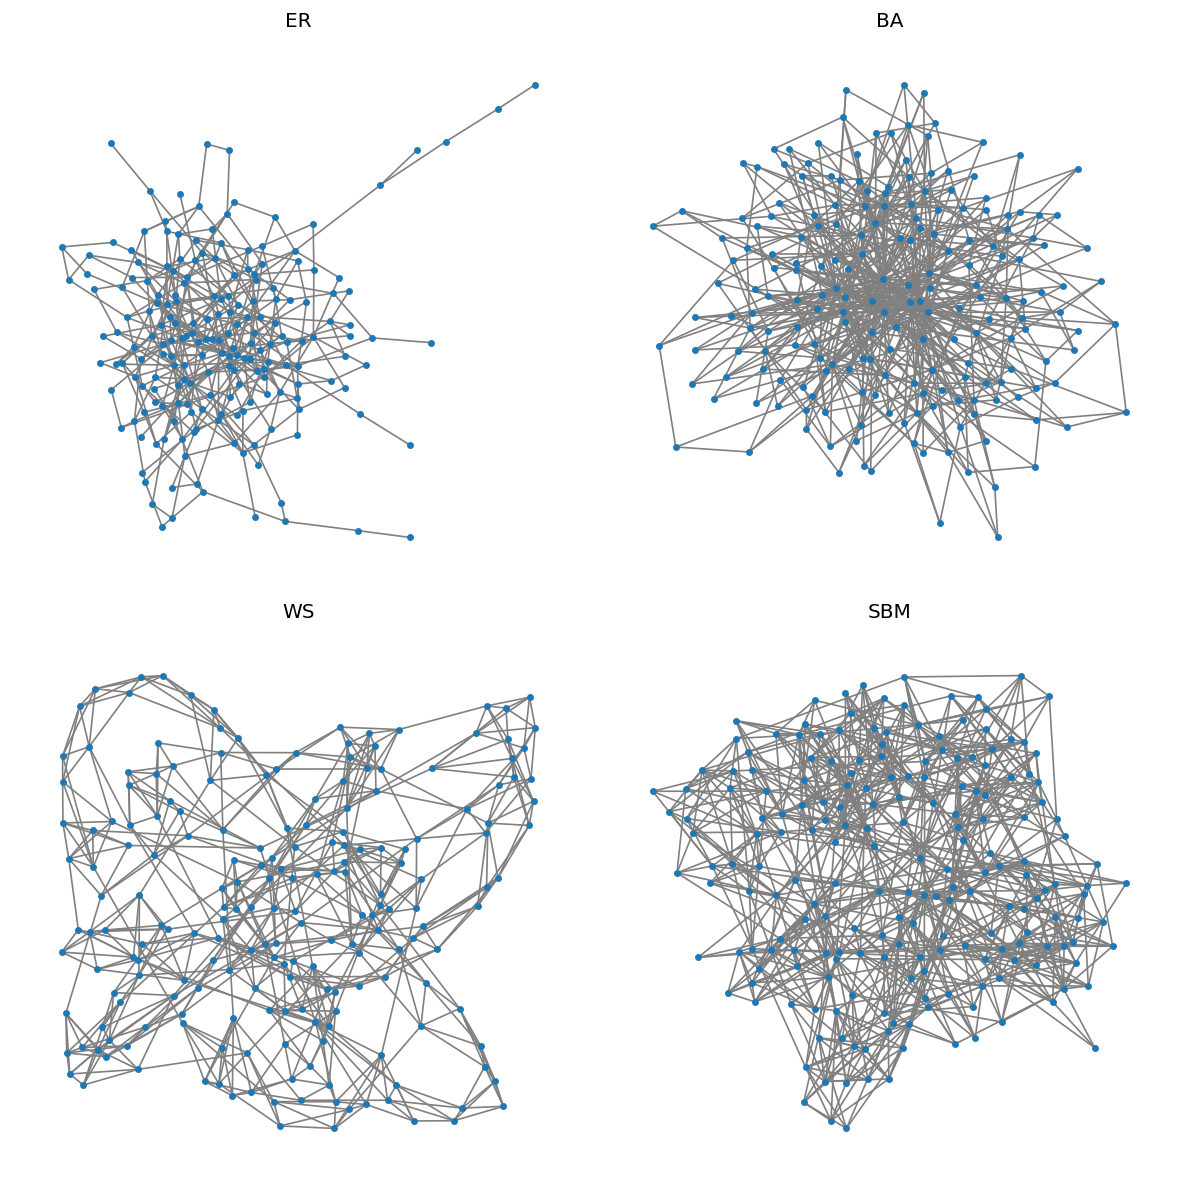

In [ ]:
# ============================================================
# VERIFY NETWORK MODULE
# ============================================================

networks = build_networks()

print_network_summary(networks)

plot_networks(networks)

# ============================================================
# SECTION 5 : DEFFUANT–WEISBUCH MODEL (DW)
# ============================================================

This section implements the asynchronous Deffuant–Weisbuch
bounded-confidence model.

Characteristics

• Pairwise asynchronous interactions
• Bounded confidence
• Symmetric opinion update
• Random edge selection
• Continuous opinions in [0,1]

The implementation follows Deffuant et al. (2000) while
remaining compatible with the CODA architecture.

In [ ]:
# ============================================================
# DEFFUANT–WEISBUCH MODEL
# ============================================================

def run_DW_on_network(
    G,
    init_opinions,
    eps=DW_EPS,
    mu=DW_MU,
    max_interactions=MAX_INTERACTIONS,
    tol=CONVERGENCE_TOL,
    check_every=500,
):
    """
    Deffuant–Weisbuch bounded-confidence model.

    Parameters
    ----------
    G : networkx.Graph

    init_opinions : dict

    eps : float
        Confidence bound.

    mu : float
        Convergence parameter.

    max_interactions : int

    tol : float

    check_every : int

    Returns
    -------
    final opinions
    interaction count
    cluster history
    polarization history
    """

    # --------------------------------------------------------
    # Initialize opinions
    # --------------------------------------------------------

    opinions = {

        node: float(init_opinions[node])

        for node in G.nodes()

    }

    previous = opinions.copy()

    edges = list(G.edges())

    cluster_history = []

    polarization_history = []

    if len(edges) == 0:

        return (

            list(opinions.values()),

            0,

            cluster_history,

            polarization_history,

        )

    stable_counter = 0

    interaction = 0

    # --------------------------------------------------------
    # Main simulation
    # --------------------------------------------------------

    while interaction < max_interactions:

        # ----------------------------------------------------
        # Random interaction
        # ----------------------------------------------------

        u, v = random.choice(edges)

        oi = opinions[u]

        oj = opinions[v]

        # ----------------------------------------------------
        # Bounded confidence update
        # ----------------------------------------------------

        if abs(oi - oj) <= eps:

            opinions[u] = np.clip(

                oi + mu * (oj - oi),

                0,

                1,

            )

            opinions[v] = np.clip(

                oj + mu * (oi - oj),

                0,

                1,

            )

        interaction += 1

        # ----------------------------------------------------
        # Record history
        # ----------------------------------------------------

        if interaction % 100 == 0:

            values = list(opinions.values())

            cluster_history.append(

                cluster_count_from_opinions(values)

            )

            polarization_history.append(

                polarization_index(values)

            )

        # ----------------------------------------------------
        # Convergence check
        # ----------------------------------------------------

        if interaction % check_every == 0:

            current = opinions.copy()

            max_change = max(

                abs(

                    current[node]

                    - previous[node]

                )

                for node in G.nodes()

            )

            if max_change < tol:

                stable_counter += 1

            else:

                stable_counter = 0

            previous = current.copy()

            if stable_counter >= 5:

                break

    return (

        list(opinions.values()),

        interaction,

        cluster_history,

        polarization_history,

    )

Model           : DW
Iterations      : 100000
Consensus       : False
Clusters        : 21
Mean Opinion    : 0.4960
Std Opinion     : 0.2523
Variance        : 0.0636
Polarization    : 0.0636


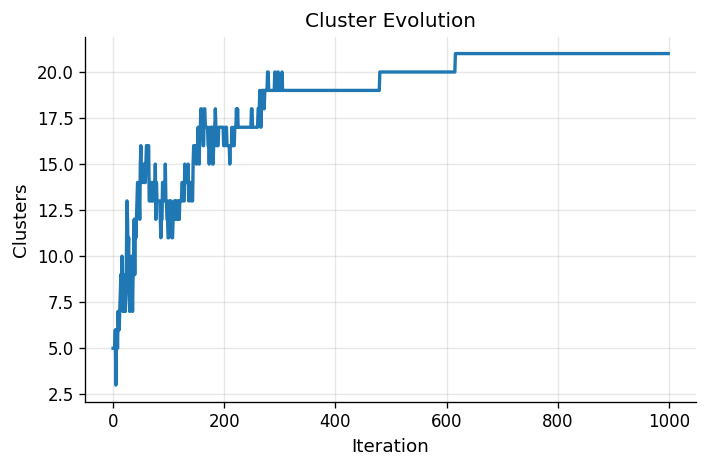

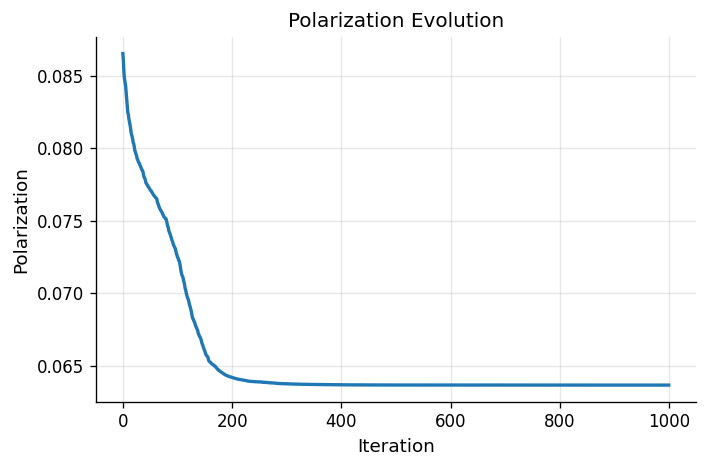

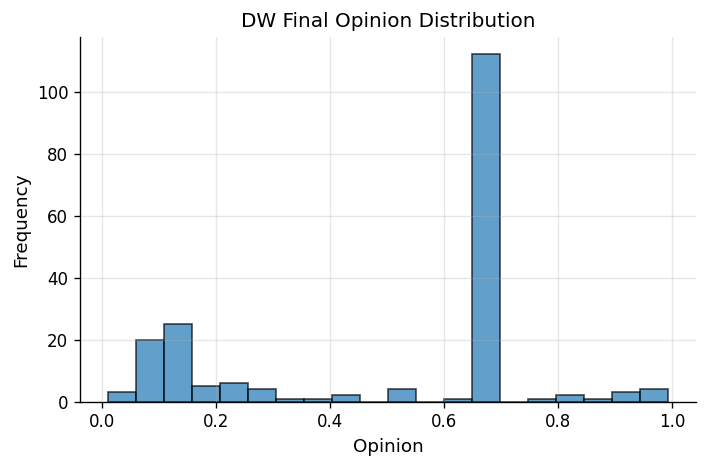

In [ ]:
# ============================================================
# DW IMPLEMENTATION
# ============================================================

networks = build_networks()

G = networks["ER"]

opinions = initialize_opinions(

    G,

    method="uniform"

)

final_op, steps, cluster_hist, pol_hist = run_DW_on_network(G,opinions)

print_simulation_report(

    model="DW",

    opinions=final_op,

    iterations=steps

)

plot_clusters(cluster_hist)

plot_polarization(pol_hist)

plot_opinion_distribution(

    final_op,

    "DW Final Opinion Distribution"

)

# ============================================================
# SECTION 6 : HEGSELMANN–KRAUSE MODEL (HK)
# ============================================================

This section implements the synchronous
Hegselmann–Krause bounded-confidence model.

Characteristics

• Synchronous opinion updates

• Local confidence neighbourhood

• Mean opinion aggregation

• Continuous opinions

• Compatible with CODA

In [ ]:
# ============================================================
# HEGSELMANN–KRAUSE MODEL
# ============================================================

def run_HK_on_network(
    G,
    init_opinions,
    eps=HK_EPS,
    max_iter=MAX_ITER,
    tol=CONVERGENCE_TOL,
):
    """
    Hegselmann–Krause bounded-confidence model.

    Parameters
    ----------
    G : networkx.Graph

    init_opinions : dict

    eps : float
        Confidence threshold.

    max_iter : int

    tol : float

    Returns
    -------
    final opinions

    iterations

    cluster history

    polarization history
    """

    # --------------------------------------------------------
    # Node ordering
    # --------------------------------------------------------

    nodes = list(G.nodes())

    node_to_index = {

        node: idx

        for idx, node in enumerate(nodes)

    }

    # --------------------------------------------------------
    # Initialize opinions
    # --------------------------------------------------------

    opinions = np.array(

        [init_opinions[node] for node in nodes],

        dtype=float

    )

    cluster_history = []

    polarization_history = []

    # --------------------------------------------------------
    # Main simulation
    # --------------------------------------------------------

    for iteration in range(1, max_iter + 1):

        previous = opinions.copy()

        updated = opinions.copy()

        # ----------------------------------------------------
        # Synchronous update
        # ----------------------------------------------------

        for i, node in enumerate(nodes):

            neighbours = list(G.neighbors(node))

            candidate_nodes = [node] + neighbours

            candidate_idx = [

                node_to_index[n]

                for n in candidate_nodes

            ]

            candidate_opinions = opinions[candidate_idx]

            opinion_distance = np.abs(

                candidate_opinions

                - opinions[i]

            )

            confidence_set = np.where(

                opinion_distance <= eps

            )[0]

            if len(confidence_set) == 0:

                continue

            updated[i] = np.mean(

                candidate_opinions[confidence_set]

            )

        # ----------------------------------------------------
        # Commit synchronous update
        # ----------------------------------------------------

        opinions = updated

        # ----------------------------------------------------
        # Record metrics
        # ----------------------------------------------------

        cluster_history.append(

            cluster_count_from_opinions(

                opinions

            )

        )

        polarization_history.append(

            polarization_index(

                opinions

            )

        )

        # ----------------------------------------------------
        # Convergence
        # ----------------------------------------------------

        max_change = np.max(

            np.abs(

                opinions - previous

            )

        )

        if max_change < tol:

            break

    return (

        opinions.tolist(),

        iteration,

        cluster_history,

        polarization_history,

    )

Model           : HK
Iterations      : 210
Consensus       : False
Clusters        : 21
Mean Opinion    : 0.4975
Std Opinion     : 0.2615
Variance        : 0.0684
Polarization    : 0.0684


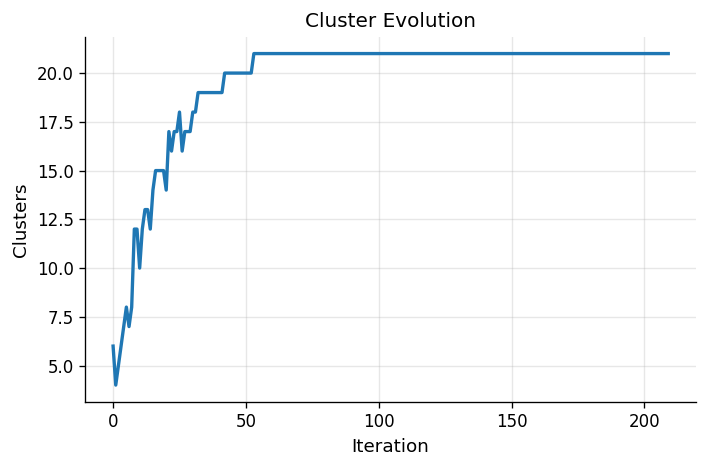

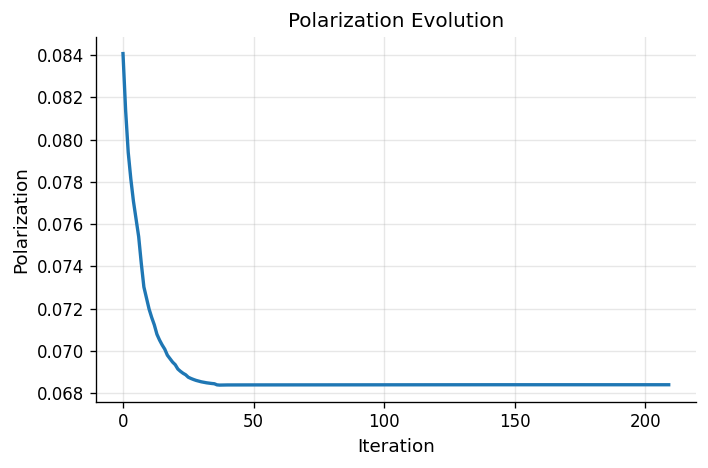

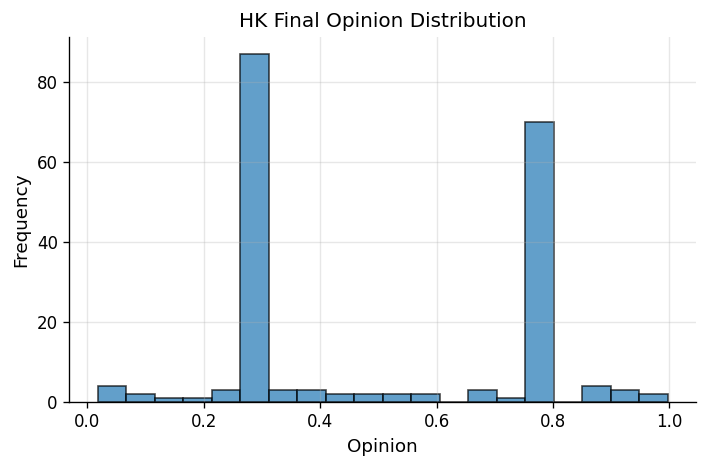

In [ ]:
# ============================================================
# HK IMPLEMENTATION
# ============================================================

networks = build_networks()

G = networks["ER"]

opinions = initialize_opinions(

    G,

    method="uniform"

)

final_op, steps, cluster_hist, pol_hist = run_HK_on_network(

    G,

    opinions

)

print_simulation_report(

    model="HK",

    opinions=final_op,

    iterations=steps

)

plot_clusters(cluster_hist)

plot_polarization(pol_hist)

plot_opinion_distribution(

    final_op,

    "HK Final Opinion Distribution"

)

# ============================================================
# SECTION 7 : CENTRALITY-WEIGHTED INTERACTION MODEL (CWIM)
# ============================================================

This section implements the proposed Centrality-Weighted
Interaction Model (CWIM).

Characteristics

• Continuous interactions over the entire neighbourhood

• Generalized Gaussian similarity kernel

• Centrality-weighted influence

• Synchronous opinion updates

• Modular centrality measures

• Compatible with the CODA architecture

The implementation follows the mathematical formulation
presented in Section 4.4.3 of the paper.

In [ ]:
# ============================================================
# CENTRALITY-WEIGHTED INTERACTION MODEL (CWIM)
# ============================================================

def run_CWIM_on_network(
    G,
    init_opinions,
    alpha=CWIM_ALPHA,
    gamma=CWIM_GAMMA,
    sigma=CWIM_SIGMA,
    eta=CWIM_ETA,
    centrality=CWIM_CENTRALITY,
    max_iter=MAX_ITER,
    tol=CONVERGENCE_TOL,
    gap_threshold=CLUSTER_GAP,
):
    """
    Centrality-Weighted Interaction Model (CWIM)

    Parameters
    ----------
    G : networkx.Graph

    init_opinions : dict

    alpha : float
        Adaptation rate.

    gamma : float
        Centrality sensitivity.

    sigma : float
        Similarity scale parameter.

    eta : float
        Similarity decay exponent.

    centrality : str
        degree
        betweenness
        eigenvector
        closeness
        pagerank

    Returns
    -------
    final opinions

    iterations

    cluster history

    polarization history
    """

    # --------------------------------------------------------
    # Parameter validation
    # --------------------------------------------------------

    if alpha <= 0 or alpha > 1:
        raise ValueError("alpha must lie in (0,1].")

    if gamma < 0:
        raise ValueError("gamma must be non-negative.")

    if sigma <= 0:
        raise ValueError("sigma must be positive.")

    if eta <= 0:
        raise ValueError("eta must be positive.")

    # --------------------------------------------------------
    # Node ordering
    # --------------------------------------------------------

    nodes = list(G.nodes())

    node_to_index = {

        node: idx

        for idx, node in enumerate(nodes)

    }

    # --------------------------------------------------------
    # Initial opinions
    # --------------------------------------------------------

    opinions = np.array(

        [init_opinions[node] for node in nodes],

        dtype=float

    )

    # --------------------------------------------------------
    # Compute centrality
    # --------------------------------------------------------

    if centrality.lower() == "degree":

        C = nx.degree_centrality(G)

    elif centrality.lower() == "betweenness":

        C = nx.betweenness_centrality(G)

    elif centrality.lower() == "closeness":

        C = nx.closeness_centrality(G)

    elif centrality.lower() == "pagerank":

        C = nx.pagerank(G)

    elif centrality.lower() == "eigenvector":

        C = nx.eigenvector_centrality_numpy(G)

    else:

        raise ValueError("Unknown centrality measure.")

    # --------------------------------------------------------
    # Normalize centrality
    # --------------------------------------------------------

    centrality_values = np.array(

        [C[node] for node in nodes]

    )

    cmin = centrality_values.min()

    cmax = centrality_values.max()

    if cmax > cmin:

        centrality_values = (

            centrality_values - cmin

        ) / (

            cmax - cmin

        )

    else:

        centrality_values[:] = 1.0

    # --------------------------------------------------------
    # History
    # --------------------------------------------------------

    cluster_history = []

    polarization_history = []

    # --------------------------------------------------------
    # Main simulation
    # --------------------------------------------------------

    for iteration in range(1, max_iter + 1):

        previous = opinions.copy()

        updated = opinions.copy()

        # ----------------------------------------------------
        # Synchronous update
        # ----------------------------------------------------

        for i, node in enumerate(nodes):

            neighbours = list(G.neighbors(node))

            if len(neighbours) == 0:
                continue

            neighbour_idx = [

                node_to_index[n]

                for n in neighbours

            ]

            neighbour_opinions = opinions[neighbour_idx]

            neighbour_centrality = centrality_values[neighbour_idx]

            # ------------------------------------------------
            # Opinion distance
            # ------------------------------------------------

            distance = np.abs(

                opinions[i]

                - neighbour_opinions

            )

            # ------------------------------------------------
            # Similarity kernel
            #
            # S_ij = exp(-(d/sigma)^eta)
            # ------------------------------------------------

            similarity = np.exp(

                -np.power(

                    distance / sigma,

                    eta

                )

            )

            # ------------------------------------------------
            # Raw influence
            #
            # I_ij = C_j^gamma * S_ij
            # ------------------------------------------------

            influence = (

                np.power(

                    neighbour_centrality,

                    gamma

                )

                * similarity

            )

            # ------------------------------------------------
            # Normalize influence weights
            # ------------------------------------------------

            weights = influence / (

                influence.sum()

                + 1e-12

            )

            # ------------------------------------------------
            # Weighted aggregation
            # ------------------------------------------------

            weighted_opinion = np.dot(

                weights,

                neighbour_opinions

            )

            # ------------------------------------------------
            # Opinion update
            # ------------------------------------------------

            updated[i] = (

                (1 - alpha)

                * opinions[i]

                +

                alpha

                * weighted_opinion

            )

        # ----------------------------------------------------
        # Commit synchronous update
        # ----------------------------------------------------

        opinions = updated

        # ----------------------------------------------------
        # Record metrics
        # ----------------------------------------------------

        cluster_history.append(

            cluster_count_from_opinions(

                opinions,

                gap_threshold

            )

        )

        polarization_history.append(

            polarization_index(opinions)

        )

        # ----------------------------------------------------
        # Convergence
        # ----------------------------------------------------

        max_change = np.max(

            np.abs(

                opinions

                - previous

            )

        )

        if max_change < tol:

            break

    return (

        opinions.tolist(),

        iteration,

        cluster_history,

        polarization_history,

    )

Model           : CWIM
Iterations      : 500
Consensus       : False
Clusters        : 3
Mean Opinion    : 0.4511
Std Opinion     : 0.0710
Variance        : 0.0050
Polarization    : 0.0050


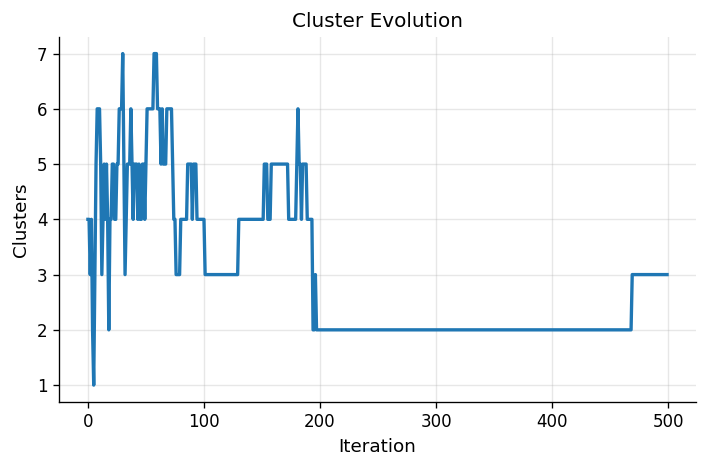

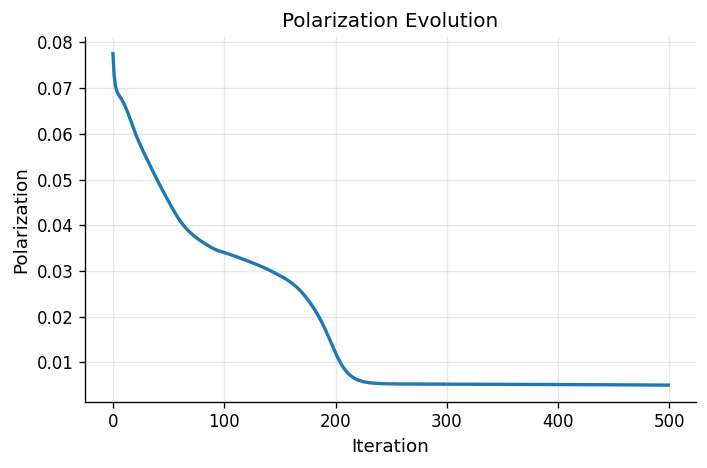

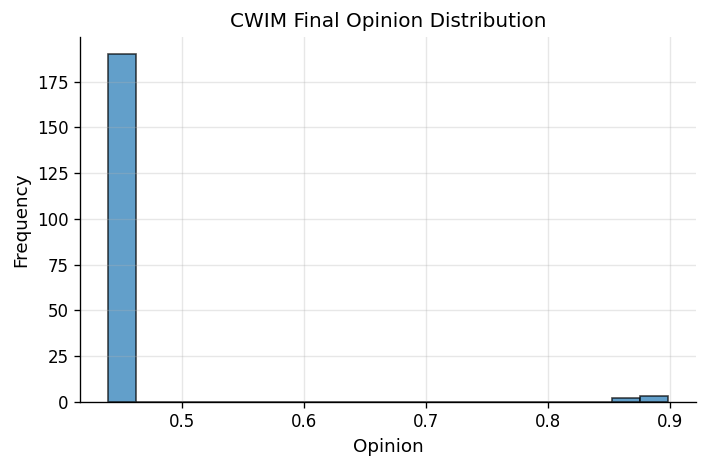

In [ ]:
# ============================================================
# VERIFY CWIM IMPLEMENTATION
# ============================================================

networks = build_networks()

G = networks["ER"]

opinions = initialize_opinions(

    G,

    method="uniform"

)

final_op, steps, cluster_hist, pol_hist = run_CWIM_on_network(

    G,

    opinions

)

print_simulation_report(

    model="CWIM",

    opinions=final_op,

    iterations=steps

)

plot_clusters(cluster_hist)

plot_polarization(pol_hist)

plot_opinion_distribution(

    final_op,

    "CWIM Final Opinion Distribution"

)

# ============================================================
# SECTION 8 : EXPERIMENT RUNNER
# ============================================================

This module executes comparative experiments under the CODA
architecture.

Features

• Common experimental pipeline

• Identical initial conditions

• Multiple network topologies

• Multiple interaction mechanisms

• Automatic metric collection

• Reproducible benchmarking

In [ ]:
# ============================================================
# MODEL REGISTRY
# ============================================================

MODEL_REGISTRY = {

    "DW": run_DW_on_network,

    "HK": run_HK_on_network,

    "CWIM": run_CWIM_on_network

}

In [ ]:
# ============================================================
# RUN SINGLE EXPERIMENT
# ============================================================

def run_single_experiment(

    G,

    model,

    initialization="uniform",

    **kwargs

):
    """
    Execute one opinion dynamics experiment.

    Returns
    -------
    dict
    """

    init_opinions = initialize_opinions(

        G,

        method=initialization

    )

    runner = MODEL_REGISTRY[model]

    final_op,iterations,cluster_history,polarization_history = runner(G,init_opinions,**kwargs)

    summary = experiment_summary(final_op)

    summary.update({

        "model": model,

        "iterations": iterations,

        "cluster_history": cluster_history,

        "polarization_history": polarization_history,

        "initial_opinions": init_opinions,

        "final_opinions": final_op

    })

    return summary

In [ ]:
# ============================================================
# COMPARE MODELS
# ============================================================

def compare_models(

    G,

    initialization="uniform"

):

    results = []

    histories = {}

    for model in MODEL_REGISTRY:

        experiment = run_single_experiment(

            G,

            model,

            initialization=initialization

        )

        results.append({

            "Model": model,

            "Iterations": experiment["iterations"],

            "Clusters": experiment["clusters"],

            "Variance": experiment["variance"],

            "Polarization": experiment["polarization"],

            "Consensus": experiment["consensus"]

        })

        histories[model] = experiment

    return pd.DataFrame(results), histories

In [ ]:
# ============================================================
# COMPARE ALL NETWORKS
# ============================================================

def benchmark_all_networks(

    initialization="uniform"

):

    benchmark = []

    networks = build_networks()

    for network_name, G in networks.items():

        table, _ = compare_models(

            G,

            initialization

        )

        table.insert(

            0,

            "Network",

            network_name

        )

        benchmark.append(table)

    return pd.concat(

        benchmark,

        ignore_index=True

    )

In [ ]:
# ============================================================
# REPLICATION STUDY
# ============================================================

def replication_study(

    n_replications=N_REPLICATIONS,

    initialization="uniform"

):

    records = []

    networks = build_networks()

    for network_name, G in networks.items():

        print(f"\n{network_name}")

        for model in MODEL_REGISTRY:

            steps = []

            clusters = []

            polarization = []

            variance = []

            consensus = []

            for r in range(n_replications):

                experiment = run_single_experiment(

                    G,

                    model,

                    initialization

                )

                steps.append(

                    experiment["iterations"]

                )

                clusters.append(

                    experiment["clusters"]

                )

                polarization.append(

                    experiment["polarization"]

                )

                variance.append(

                    experiment["variance"]

                )

                consensus.append(

                    experiment["consensus"]

                )

            step_stats = summary_statistics(steps)

            cluster_stats = summary_statistics(clusters)

            pol_stats = summary_statistics(polarization)

            var_stats = summary_statistics(variance)

            records.append({

                "network": network_name,

                "model": model,

                "consensus_rate":

                    np.mean(consensus),

                # ------------------

                "steps_mean":

                    step_stats["mean"],

                "steps_std":

                    step_stats["std"],

                "steps_median":

                    step_stats["median"],

                "steps_iqr":

                    step_stats["iqr"],

                # ------------------

                "clusters_mean":

                    cluster_stats["mean"],

                "clusters_std":

                    cluster_stats["std"],

                "clusters_median":

                    cluster_stats["median"],

                "clusters_iqr":

                    cluster_stats["iqr"],

                # ------------------

                "polarization_mean":

                    pol_stats["mean"],

                "polarization_std":

                    pol_stats["std"],

                "polarization_median":

                    pol_stats["median"],

                "polarization_iqr":

                    pol_stats["iqr"],

                # ------------------

                "variance_mean":

                    var_stats["mean"],

                "variance_std":

                    var_stats["std"],

                "variance_median":

                    var_stats["median"],

                "variance_iqr":

                    var_stats["iqr"]

            })

    return pd.DataFrame(records)

In [ ]:
# ============================================================
# QUICK BENCHMARK
# ============================================================

benchmark = benchmark_all_networks()

display(benchmark)

,Network,Model,Iterations,Clusters,Variance,Polarization,Consensus
0,ER,DW,100000,17,5.778822e-02,5.778822e-02,False
1,ER,HK,190,17,2.429625e-02,2.429625e-02,False
2,ER,CWIM,500,2,4.787284e-03,4.787284e-03,False
3,BA,DW,100000,13,6.760738e-02,6.760738e-02,False
4,BA,HK,62,9,1.504405e-02,1.504405e-02,False
5,BA,CWIM,111,1,4.940086e-12,4.940086e-12,True
6,WS,DW,100000,12,6.041087e-02,6.041087e-02,False
7,WS,HK,500,13,5.299359e-02,5.299359e-02,False
8,WS,CWIM,500,4,4.886181e-02,4.886181e-02,False
9,SBM,DW,100000,3,4.807791e-02,4.807791e-02,False


In [ ]:
# ============================================================
# COMPLETE REPLICATION STUDY
# ============================================================

results = replication_study(

    n_replications=20,

    initialization="uniform"

)

display(results)

results.to_csv(

    "CODA_Benchmark.csv",

    index=False

)


ER

BA

WS

SBM


,network,model,consensus_rate,steps_mean,steps_std,steps_median,steps_iqr,clusters_mean,clusters_std,clusters_median,clusters_iqr,polarization_mean,polarization_std,polarization_median,polarization_iqr,variance_mean,variance_std,variance_median,variance_iqr
0,ER,DW,0.00,99675.00,1416.642157,100000.0,0.00,16.25,2.643388,15.5,3.00,0.059594,0.010564,6.197966e-02,0.013488,0.059594,0.010564,6.197966e-02,0.013488
1,ER,HK,0.00,230.85,89.878404,214.5,86.50,13.65,2.219797,14.0,3.00,0.031811,0.009461,3.017635e-02,0.012888,0.031811,0.009461,3.017635e-02,0.012888
2,ER,CWIM,0.50,432.55,84.716276,500.0,154.25,2.20,1.777639,1.5,1.25,0.005882,0.010090,8.981733e-04,0.006816,0.005882,0.010090,8.981733e-04,0.006816
3,BA,DW,0.00,99025.00,3156.243812,100000.0,0.00,12.65,2.868362,12.5,3.00,0.060481,0.008072,6.131843e-02,0.010710,0.060481,0.008072,6.131843e-02,0.010710
4,BA,HK,0.00,122.15,73.025526,89.0,46.75,10.65,2.706936,10.0,2.75,0.026045,0.017519,1.801058e-02,0.021060,0.026045,0.017519,1.801058e-02,0.021060
5,BA,CWIM,0.20,353.60,149.884089,388.5,281.25,2.05,0.668954,2.0,0.25,0.052492,0.030781,6.345710e-02,0.025332,0.052492,0.030781,6.345710e-02,0.025332
6,WS,DW,0.00,100000.00,0.000000,100000.0,0.00,11.30,2.590367,11.0,3.25,0.056390,0.010574,5.570860e-02,0.009064,0.056390,0.010574,5.570860e-02,0.009064
7,WS,HK,0.00,367.00,91.695692,362.5,166.25,10.65,2.006863,10.0,2.25,0.032944,0.015612,2.802524e-02,0.019260,0.032944,0.015612,2.802524e-02,0.019260
8,WS,CWIM,0.45,500.00,0.000000,500.0,0.00,2.15,1.458595,2.0,1.25,0.005268,0.010059,2.614406e-03,0.005022,0.005268,0.010059,2.614406e-03,0.005022
9,SBM,DW,0.00,100000.00,0.000000,100000.0,0.00,5.80,2.039608,6.0,2.25,0.052756,0.010444,5.200743e-02,0.013104,0.052756,0.010444,5.200743e-02,0.013104


In [ ]:
# ============================================================
# RANK RESULTS
# ============================================================

print("\nLowest Polarization")

display(

    results.sort_values(

        "polarization_mean"

    ).head()

)

print("\nLargest Cluster Count")

display(

    results.sort_values(

        "clusters_mean",

        ascending=False

    ).head()

)

print("\nFastest Convergence")

display(

    results.sort_values(

        "steps_mean"

    ).head()

)


Lowest Polarization


,network,model,consensus_rate,steps_mean,steps_std,steps_median,steps_iqr,clusters_mean,clusters_std,clusters_median,clusters_iqr,polarization_mean,polarization_std,polarization_median,polarization_iqr,variance_mean,variance_std,variance_median,variance_iqr
8,WS,CWIM,0.45,500.00,0.000000,500.0,0.00,2.15,1.458595,2.0,1.25,0.005268,0.010059,2.614406e-03,0.005022,0.005268,0.010059,2.614406e-03,0.005022
2,ER,CWIM,0.50,432.55,84.716276,500.0,154.25,2.20,1.777639,1.5,1.25,0.005882,0.010090,8.981733e-04,0.006816,0.005882,0.010090,8.981733e-04,0.006816
10,SBM,HK,0.00,131.35,59.776479,104.0,68.75,4.80,1.536229,5.0,2.25,0.010820,0.014232,5.543432e-03,0.006167,0.010820,0.014232,5.543432e-03,0.006167
11,SBM,CWIM,0.70,421.60,94.441728,482.5,170.50,1.30,0.458258,1.0,1.00,0.013777,0.021120,2.086740e-10,0.041341,0.013777,0.021120,2.086740e-10,0.041341
4,BA,HK,0.00,122.15,73.025526,89.0,46.75,10.65,2.706936,10.0,2.75,0.026045,0.017519,1.801058e-02,0.021060,0.026045,0.017519,1.801058e-02,0.021060



Largest Cluster Count


,network,model,consensus_rate,steps_mean,steps_std,steps_median,steps_iqr,clusters_mean,clusters_std,clusters_median,clusters_iqr,polarization_mean,polarization_std,polarization_median,polarization_iqr,variance_mean,variance_std,variance_median,variance_iqr
0,ER,DW,0.0,99675.00,1416.642157,100000.0,0.00,16.25,2.643388,15.5,3.00,0.059594,0.010564,0.061980,0.013488,0.059594,0.010564,0.061980,0.013488
1,ER,HK,0.0,230.85,89.878404,214.5,86.50,13.65,2.219797,14.0,3.00,0.031811,0.009461,0.030176,0.012888,0.031811,0.009461,0.030176,0.012888
3,BA,DW,0.0,99025.00,3156.243812,100000.0,0.00,12.65,2.868362,12.5,3.00,0.060481,0.008072,0.061318,0.010710,0.060481,0.008072,0.061318,0.010710
6,WS,DW,0.0,100000.00,0.000000,100000.0,0.00,11.30,2.590367,11.0,3.25,0.056390,0.010574,0.055709,0.009064,0.056390,0.010574,0.055709,0.009064
7,WS,HK,0.0,367.00,91.695692,362.5,166.25,10.65,2.006863,10.0,2.25,0.032944,0.015612,0.028025,0.019260,0.032944,0.015612,0.028025,0.019260



Fastest Convergence


,network,model,consensus_rate,steps_mean,steps_std,steps_median,steps_iqr,clusters_mean,clusters_std,clusters_median,clusters_iqr,polarization_mean,polarization_std,polarization_median,polarization_iqr,variance_mean,variance_std,variance_median,variance_iqr
4,BA,HK,0.0,122.15,73.025526,89.0,46.75,10.65,2.706936,10.0,2.75,0.026045,0.017519,0.018011,0.021060,0.026045,0.017519,0.018011,0.021060
10,SBM,HK,0.0,131.35,59.776479,104.0,68.75,4.80,1.536229,5.0,2.25,0.010820,0.014232,0.005543,0.006167,0.010820,0.014232,0.005543,0.006167
1,ER,HK,0.0,230.85,89.878404,214.5,86.50,13.65,2.219797,14.0,3.00,0.031811,0.009461,0.030176,0.012888,0.031811,0.009461,0.030176,0.012888
5,BA,CWIM,0.2,353.60,149.884089,388.5,281.25,2.05,0.668954,2.0,0.25,0.052492,0.030781,0.063457,0.025332,0.052492,0.030781,0.063457,0.025332
7,WS,HK,0.0,367.00,91.695692,362.5,166.25,10.65,2.006863,10.0,2.25,0.032944,0.015612,0.028025,0.019260,0.032944,0.015612,0.028025,0.019260


In [ ]:
# ============================================================
# VERIFY EXPERIMENT RUNNER
# ============================================================

print("="*60)

print("Experiment Runner Successfully Loaded")

print("="*60)

print("Registered Models")

print(MODEL_REGISTRY.keys())

print()

print("Networks")

print(build_networks().keys())

print()

print("Replications =",N_REPLICATIONS)

Experiment Runner Successfully Loaded
Registered Models
dict_keys(['DW', 'HK', 'CWIM'])

Networks
dict_keys(['ER', 'BA', 'WS', 'SBM'])

Replications = 20


# ============================================================
# SECTION 9 : VISUALIZATION
# ============================================================

This module provides visualization utilities for analysing
opinion dynamics experiments.

Supported visualizations

1. Opinion Evolution
2. Cluster Evolution
3. Polarization Evolution
4. Opinion Distributions
5. Comparative Visualizations

The module is independent of the interaction mechanism and can
therefore visualize DW, HK, CWIM, and future models implemented
within CODA.

In [ ]:
# ============================================================
# OPINION DISTRIBUTION
# ============================================================

def plot_opinion_distribution(
    opinions,
    title="Opinion Distribution",
    bins=20,
):

    plt.figure(figsize=(6,4))

    plt.hist(
        opinions,
        bins=bins,
        edgecolor="black",
        alpha=0.75
    )

    plt.xlabel("Opinion")

    plt.ylabel("Frequency")

    plt.title(title)

    plt.tight_layout()

    plt.show()

In [ ]:
# ============================================================
# OPINION EVOLUTION
# ============================================================

def plot_opinion_evolution(
    initial_opinions,
    final_opinions,
    title="Opinion Evolution",
):

    initial = np.sort(list(initial_opinions.values()))
    final = np.sort(final_opinions)

    plt.figure(figsize=(7,4))

    plt.plot(
        initial,
        label="Initial",
        linewidth=2
    )

    plt.plot(
        final,
        label="Final",
        linewidth=2
    )

    plt.xlabel("Sorted Agents")

    plt.ylabel("Opinion")

    plt.title(title)

    plt.legend()

    plt.tight_layout()

    plt.show()

In [ ]:
# ============================================================
# CLUSTER EVOLUTION
# ============================================================

def plot_cluster_evolution(
    cluster_history,
    model=""
):

    plt.figure(figsize=(6,4))

    plt.plot(
        cluster_history,
        linewidth=2
    )

    plt.xlabel("Iteration")

    plt.ylabel("Number of Clusters")

    plt.title(f"{model} : Cluster Evolution")

    plt.tight_layout()

    plt.show()

In [ ]:
# ============================================================
# POLARIZATION EVOLUTION
# ============================================================

def plot_polarization_evolution(
    polarization_history,
    model=""
):

    plt.figure(figsize=(6,4))

    plt.plot(
        polarization_history,
        linewidth=2
    )

    plt.xlabel("Iteration")

    plt.ylabel("Polarization")

    plt.title(f"{model} : Polarization Evolution")

    plt.tight_layout()

    plt.show()

In [ ]:
# ============================================================
# INITIAL VS FINAL DISTRIBUTION
# ============================================================

def compare_distributions(
    initial_opinions,
    final_opinions,
    model=""
):

    plt.figure(figsize=(7,4))

    plt.hist(
        list(initial_opinions.values()),
        bins=20,
        alpha=0.60,
        label="Initial"
    )

    plt.hist(
        final_opinions,
        bins=20,
        alpha=0.60,
        label="Final"
    )

    plt.xlabel("Opinion")

    plt.ylabel("Frequency")

    plt.title(f"{model} : Initial vs Final")

    plt.legend()

    plt.tight_layout()

    plt.show()

In [ ]:
# ============================================================
# MODEL COMPARISON
# ============================================================

def compare_models_histogram(results):

    plt.figure(figsize=(7,4))

    width = 0.25

    models = results["Model"]

    x = np.arange(len(models))

    plt.bar(
        x-width,
        results["Clusters"],
        width,
        label="Clusters"
    )

    plt.bar(
        x,
        results["Variance"],
        width,
        label="Variance"
    )

    plt.bar(
        x+width,
        results["Polarization"],
        width,
        label="Polarization"
    )

    plt.xticks(
        x,
        models
    )

    plt.title("Model Comparison")

    plt.legend()

    plt.tight_layout()

    plt.show()

In [ ]:
# ============================================================
# COMPLETE VISUAL REPORT
# ============================================================

def visualize_experiment(experiment):

    model = experiment["model"]

    print(f"\nVisualization : {model}")

    plot_opinion_evolution(
        experiment["initial_opinions"],
        experiment["final_opinions"],
        model
    )

    plot_cluster_evolution(
        experiment["cluster_history"],
        model
    )

    plot_polarization_evolution(
        experiment["polarization_history"],
        model
    )

    compare_distributions(
        experiment["initial_opinions"],
        experiment["final_opinions"],
        model
    )


Visualization : CWIM


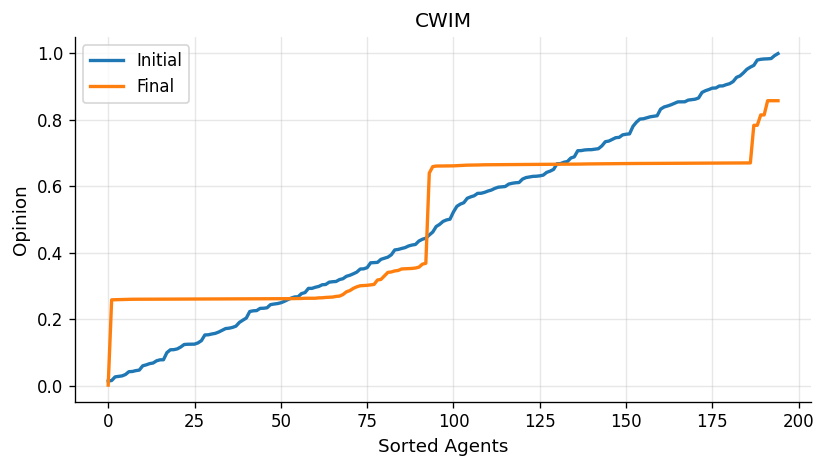

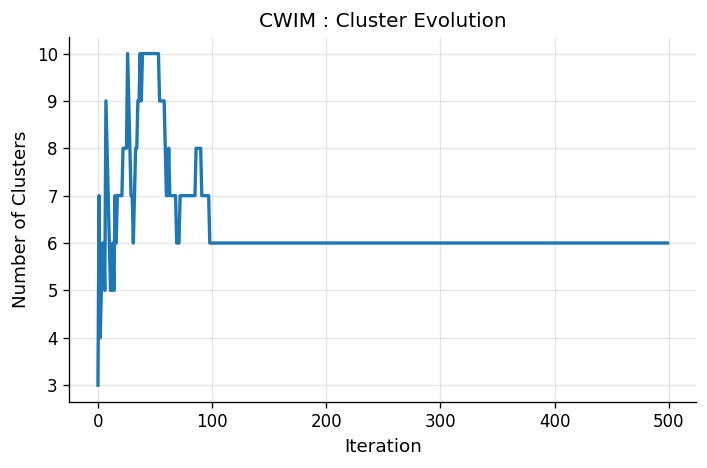

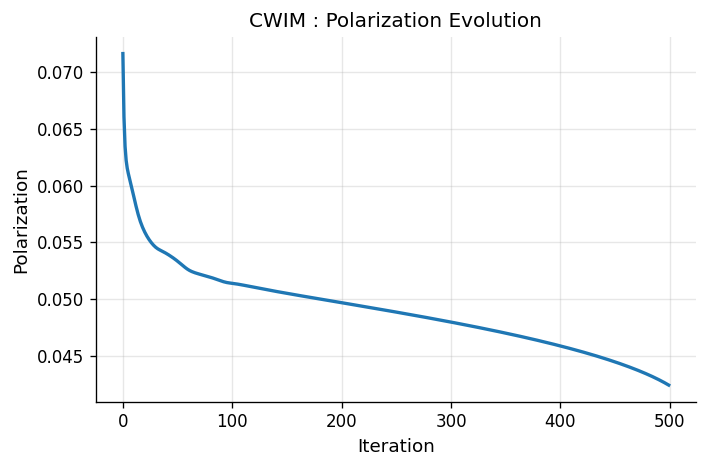

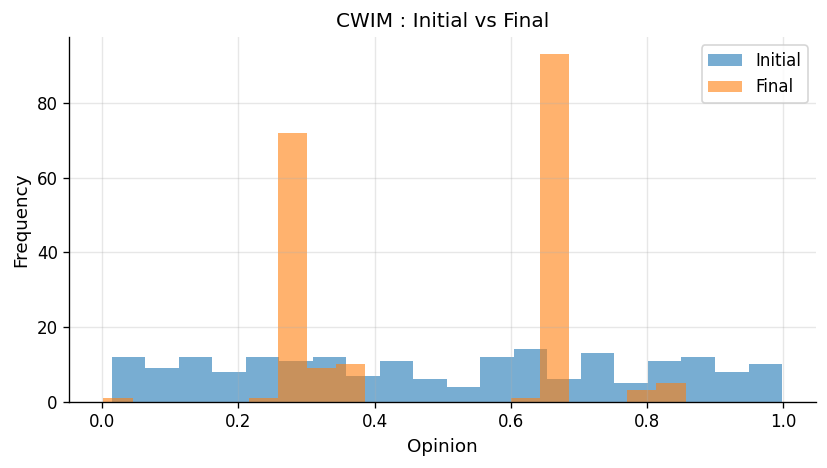

In [ ]:
# ============================================================
# EXAMPLE
# ============================================================

networks = build_networks()

G = networks["ER"]

experiment = run_single_experiment(

    G,

    model="CWIM",

    initialization="uniform"

)

visualize_experiment(experiment)

# ============================================================
# SECTION 10 : CWIM PARAMETER SENSITIVITY ANALYSIS
# ============================================================

This module performs a systematic sensitivity analysis of the
Centrality-Weighted Interaction Model (CWIM).

The analysis explores the parameter space

• σ (similarity scale)
• γ (centrality sensitivity)
• α (adaptation rate)

across multiple network topologies.

Each parameter combination is evaluated using multiple
independent replications.

Outputs

• Raw experiment data

• Summary statistics

• CSV export

• Heatmaps

The objective is to identify parameter regions producing
qualitatively different opinion dynamics rather than tuning
a single optimal parameter configuration.

In [ ]:
# ============================================================
# PARAMETER GRID
# ============================================================

SIGMA_VALUES = [

    0.02,

    0.05,

    0.10,

    0.20,

    0.40

]

GAMMA_VALUES = [

    0.5,

    1.0,

    2.0

]

ALPHA_VALUES = [

    0.05,

    0.10,

    0.20,

    0.30

]

PARAMETER_GRID = list(

    product(

        SIGMA_VALUES,

        GAMMA_VALUES,

        ALPHA_VALUES

    )

)

print(

    "Parameter combinations:",

    len(PARAMETER_GRID)

)

Parameter combinations: 60


In [ ]:
# ============================================================
# SINGLE CWIM EXPERIMENT
# ============================================================

def run_cwim_configuration(

    G,

    sigma,

    gamma,

    alpha,

    initialization="uniform",

):

    init = initialize_opinions(

        G,

        method=initialization

    )

    final,iterations,clusters,polarization = run_CWIM_on_network(

        G,

        init,

        sigma=sigma,

        gamma=gamma,

        alpha=alpha

    )

    summary = experiment_summary(final)

    summary["iterations"] = iterations

    return summary

In [ ]:
# ============================================================
# COMPLETE PARAMETER STUDY
# ============================================================

def cwim_parameter_sensitivity(

    replications=20,

    initialization="uniform"

):

    raw_results = []

    networks = build_networks()

    total_runs = (

        len(networks)

        * len(PARAMETER_GRID)

        * replications

    )

    run = 1

    for network_name, G in networks.items():

        print(f"\n{network_name}")

        for sigma, gamma, alpha in PARAMETER_GRID:

            print(

                f"{run}/{total_runs}",

                end="\r"

            )

            for r in range(replications):

                summary = run_cwim_configuration(

                    G,

                    sigma,

                    gamma,

                    alpha,

                    initialization

                )

                raw_results.append({

                    "network":

                        network_name,

                    "sigma":

                        sigma,

                    "gamma":

                        gamma,

                    "alpha":

                        alpha,

                    "replication":

                        r+1,

                    "iterations":

                        summary["iterations"],

                    "clusters":

                        summary["clusters"],

                    "variance":

                        summary["variance"],

                    "polarization":

                        summary["polarization"],

                    "consensus":

                        summary["consensus"]

                })

            run += 1

    return pd.DataFrame(raw_results)

In [ ]:
# ============================================================
# SUMMARY TABLE
# ============================================================

def summarize_parameter_study(

    raw

):

    summary = (

        raw

        .groupby(

            [

                "network",

                "sigma",

                "gamma",

                "alpha"

            ]

        )

        .agg(

            iterations_mean=("iterations","mean"),

            iterations_std=("iterations","std"),

            iterations_median=("iterations","median"),

            clusters_mean=("clusters","mean"),

            clusters_std=("clusters","std"),

            polarization_mean=("polarization","mean"),

            polarization_std=("polarization","std"),

            variance_mean=("variance","mean"),

            variance_std=("variance","std"),

            consensus_rate=("consensus","mean")

        )

        .reset_index()

    )

    return summary

In [ ]:
# ============================================================
# EXPORT
# ============================================================

def export_parameter_study(

    raw,

    summary

):

    raw.to_csv(

        "CWIM_Raw_Results.csv",

        index=False

    )

    summary.to_csv(

        "CWIM_Summary.csv",

        index=False

    )

    print(

        "CSV files exported."

    )

In [ ]:
# ============================================================
# HEATMAPS
# ============================================================

def heatmap_parameter(

    summary,

    network,

    metric,

    alpha

):

    subset = summary[

        (summary.network==network)

        &

        (summary.alpha==alpha)

    ]

    pivot = subset.pivot(

        index="sigma",

        columns="gamma",

        values=metric

    )

    plt.figure(figsize=(6,5))

    plt.imshow(

        pivot,

        aspect="auto",

        origin="lower"

    )

    plt.xticks(

        range(len(pivot.columns)),

        pivot.columns

    )

    plt.yticks(

        range(len(pivot.index)),

        pivot.index

    )

    plt.xlabel("Gamma")

    plt.ylabel("Sigma")

    plt.title(

        f"{metric}\n{network} α={alpha}"

    )

    plt.colorbar()

    plt.show()

    return pivot

In [ ]:
# ============================================================
# RUN COMPLETE SENSITIVITY ANALYSIS
# ============================================================

raw_results = cwim_parameter_sensitivity(

    replications=20

)

summary = summarize_parameter_study(

    raw_results

)

export_parameter_study(

    raw_results,

    summary

)

display(summary.head())


ER

BA

WS

SBM
CSV files exported.


,network,sigma,gamma,alpha,iterations_mean,iterations_std,iterations_median,clusters_mean,clusters_std,polarization_mean,polarization_std,variance_mean,variance_std,consensus_rate
0,BA,0.02,0.5,0.05,500.00,0.000000,500.0,15.90,1.860956,0.086353,0.009671,0.086353,0.009671,0.0
1,BA,0.02,0.5,0.10,495.85,18.559364,500.0,15.10,2.074913,0.080322,0.008594,0.080322,0.008594,0.0
2,BA,0.02,0.5,0.20,484.55,50.622935,500.0,15.15,1.725200,0.082072,0.011138,0.082072,0.011138,0.0
3,BA,0.02,0.5,0.30,492.00,24.700309,500.0,14.65,1.980829,0.079052,0.013010,0.079052,0.013010,0.0
4,BA,0.02,1.0,0.05,500.00,0.000000,500.0,15.40,1.902906,0.081810,0.013577,0.081810,0.013577,0.0


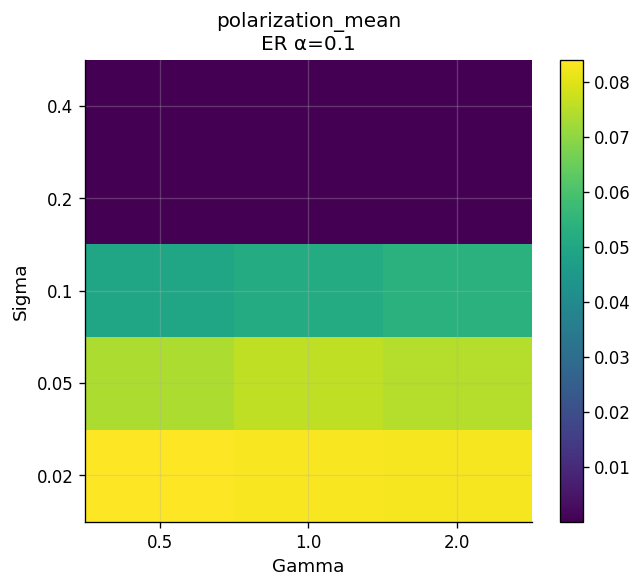

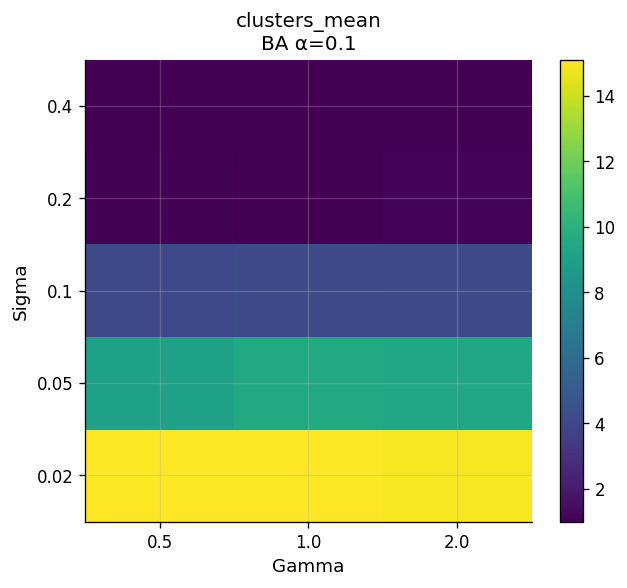

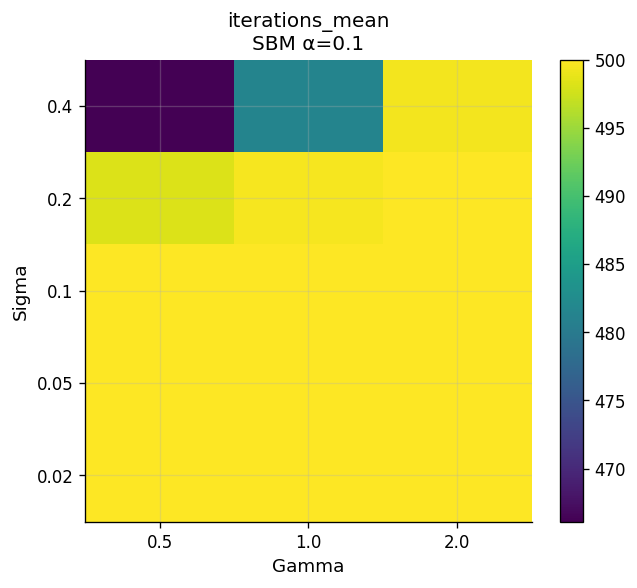

gamma,0.5,1.0,2.0
sigma,,,
0.02,500.0,500.00,500.00
0.05,500.0,500.00,500.00
0.10,500.0,500.00,500.00
0.20,498.2,499.60,500.00
0.40,466.1,481.35,499.45


In [ ]:
# ============================================================
# HEATMAP EXAMPLES
# ============================================================

heatmap_parameter(

    summary,

    network="ER",

    metric="polarization_mean",

    alpha=0.10

)

heatmap_parameter(

    summary,

    network="BA",

    metric="clusters_mean",

    alpha=0.10

)

heatmap_parameter(

    summary,

    network="SBM",

    metric="iterations_mean",

    alpha=0.10

)

In [ ]:
# ============================================================
# PARAMETER REGIONS
# ============================================================

summary.sort_values(

    [

        "polarization_mean",

        "clusters_mean"

    ],

    ascending=[

        False,

        False

    ]

).head(20)

,network,sigma,gamma,alpha,iterations_mean,iterations_std,iterations_median,clusters_mean,clusters_std,polarization_mean,polarization_std,variance_mean,variance_std,consensus_rate
0,BA,0.02,0.5,0.05,500.00,0.000000,500.0,15.90,1.860956,0.086353,0.009671,0.086353,0.009671,0.0
8,BA,0.02,2.0,0.05,498.10,8.497058,500.0,15.10,2.221901,0.085480,0.012610,0.085480,0.012610,0.0
64,ER,0.02,1.0,0.05,500.00,0.000000,500.0,18.85,2.368099,0.084872,0.007415,0.084872,0.007415,0.0
181,WS,0.02,0.5,0.10,492.05,35.553481,500.0,19.50,2.328315,0.084677,0.007577,0.084677,0.007577,0.0
5,BA,0.02,1.0,0.10,476.30,59.228460,500.0,15.05,2.543826,0.084449,0.009409,0.084449,0.009409,0.0
185,WS,0.02,1.0,0.10,494.95,22.584287,500.0,18.40,1.698296,0.084154,0.008268,0.084154,0.008268,0.0
61,ER,0.02,0.5,0.10,500.00,0.000000,500.0,19.10,1.618967,0.083992,0.009023,0.083992,0.009023,0.0
9,BA,0.02,2.0,0.10,471.45,91.674180,500.0,14.95,2.114486,0.083616,0.011228,0.083616,0.011228,0.0
120,SBM,0.02,0.5,0.05,500.00,0.000000,500.0,18.80,1.735087,0.083553,0.007204,0.083553,0.007204,0.0
65,ER,0.02,1.0,0.10,496.90,13.863621,500.0,19.25,2.425197,0.083194,0.007170,0.083194,0.007170,0.0


# ============================================================
# SECTION 11 : FIGURES
# ============================================================

This module generates figures from the
the experimental results.

All figures use

• consistent typography

• high-resolution output



In [ ]:
# ============================================================
# PUBLICATION STYLE
# ============================================================

def set_publication_style():

    plt.rcParams.update({

        "figure.figsize": (6,4),

        "figure.dpi":300,

        "savefig.dpi":600,

        "font.family":"Times New Roman",

        "font.size":11,

        "axes.labelsize":11,

        "axes.titlesize":12,

        "legend.fontsize":10,

        "xtick.labelsize":10,

        "ytick.labelsize":10,

        "axes.linewidth":1,

        "lines.linewidth":2,

        "pdf.fonttype":42,

        "ps.fonttype":42

    })

In [ ]:
# ============================================================
# SAVE FIGURE
# ============================================================

from pathlib import Path

FIGURE_DIR = Path("Figures")

FIGURE_DIR.mkdir(exist_ok=True)


def save_figure(

    filename,

    transparent=False

):

    plt.tight_layout()

    plt.savefig(

        FIGURE_DIR / f"{filename}.png",

        bbox_inches="tight",

        transparent=transparent

    )

    plt.savefig(

        FIGURE_DIR / f"{filename}.pdf",

        bbox_inches="tight",

        transparent=transparent

    )

    plt.savefig(

        FIGURE_DIR / f"{filename}.svg",

        bbox_inches="tight",

        transparent=transparent

    )

    plt.close()

In [ ]:
# ============================================================
# FIGURE 1
# OPINION EVOLUTION
# ============================================================

def figure_opinion_evolution(

    experiment,

    filename

):

    set_publication_style()

    plot_opinion_evolution(

        experiment["initial_opinions"],

        experiment["final_opinions"],

        title=""

    )

    save_figure(filename)

In [ ]:
# ============================================================
# FIGURE 2
# ============================================================

def figure_cluster_evolution(

    experiment,

    filename

):

    set_publication_style()

    plot_cluster_evolution(

        experiment["cluster_history"],

        model=""

    )

    save_figure(filename)

In [ ]:
# ============================================================
# FIGURE 3
# ============================================================

def figure_polarization(

    experiment,

    filename

):

    set_publication_style()

    plot_polarization_evolution(

        experiment["polarization_history"],

        model=""

    )

    save_figure(filename)

In [ ]:
# ============================================================
# FIGURE 4
# ============================================================

def figure_distribution(

    experiment,

    filename

):

    set_publication_style()

    compare_distributions(

        experiment["initial_opinions"],

        experiment["final_opinions"],

        model=""

    )

    save_figure(filename)

In [ ]:
# ============================================================
# FIGURE 5
# ============================================================

def figure_heatmap(

    summary,

    network,

    metric,

    alpha,

    filename

):

    set_publication_style()

    heatmap_parameter(

        summary,

        network,

        metric,

        alpha

    )

    save_figure(filename)

In [ ]:
# ============================================================
# FIGURE 5
# ============================================================

def figure_heatmap(

    summary,

    network,

    metric,

    alpha,

    filename

):

    set_publication_style()

    heatmap_parameter(

        summary,

        network,

        metric,

        alpha

    )

    save_figure(filename)

In [ ]:
# ============================================================
# FIGURE 6
# ============================================================

def figure_model_comparison(

    benchmark,

    metric,

    filename

):

    set_publication_style()

    pivot = benchmark.pivot(

        index="network",

        columns="model",

        values=metric

    )

    ax = pivot.plot(

        kind="bar"

    )

    ax.set_ylabel(metric)

    ax.set_xlabel("Network")

    plt.legend(title="Model")

    save_figure(filename)

In [ ]:
# ============================================================
# FIGURE 7
# ============================================================

def figure_networks(

    networks

):

    set_publication_style()

    plot_networks(networks)

    save_figure("Network_Topologies")

In [ ]:
# ============================================================
# EXPORT ALL FIGURES
# ============================================================

def export_publication_figures(

    experiment,

    summary,

    benchmark,

    networks

):

    figure_opinion_evolution(

        experiment,

        "Opinion_Evolution"

    )

    figure_cluster_evolution(

        experiment,

        "Cluster_Evolution"

    )

    figure_polarization(

        experiment,

        "Polarization"

    )

    figure_distribution(

        experiment,

        "Opinion_Distribution"

    )

    figure_heatmap(

        summary,

        network="ER",

        metric="polarization_mean",

        alpha=0.10,

        filename="Heatmap_ER"

    )

    figure_model_comparison(

        benchmark,

        metric="polarization_mean",

        filename="Comparison"

    )

    figure_networks(networks)

    print(

        "Figures exported to:",

        FIGURE_DIR.resolve()

    )

In [ ]:
# ============================================================
# GENERATE PAPER FIGURES
# ============================================================

networks = build_networks()

G = networks["ER"]

experiment = run_single_experiment(

    G,

    model="CWIM"

)

benchmark = replication_study(

    n_replications=10

)

raw = cwim_parameter_sensitivity(

    replications=5

)

summary = summarize_parameter_study(raw)

export_publication_figures(

    experiment,

    summary,

    benchmark,

    networks

)

NameError: name 'build_networks' is not defined

# ============================================================
# SECTION 12 : SUMMARY TABLES
# ============================================================

This module generates summary tables from
the experimental results produced by CODA.

The tables summarize

• network characteristics

• model performance

• convergence behaviour

• opinion clustering

• polarization

• parameter sensitivity



In [ ]:
# ============================================================
# TABLE FORMATTING
# ============================================================

def format_table(df, decimals=3):
    """
    Format numeric columns for publication.
    """

    formatted = df.copy()

    numeric_cols = formatted.select_dtypes(include=[np.number]).columns

    formatted[numeric_cols] = formatted[numeric_cols].round(decimals)

    return formatted

In [ ]:
# ============================================================
# TABLE 1
# NETWORK CHARACTERISTICS
# ============================================================

def create_network_table(networks):

    rows = []

    for name, G in networks.items():

        rows.append({

            "Network": name,

            "Nodes": G.number_of_nodes(),

            "Edges": G.number_of_edges(),

            "Density": nx.density(G),

            "Average Degree":

                np.mean(

                    [d for _, d in G.degree()]

                ),

            "Average Clustering":

                nx.average_clustering(G)

        })

    table = pd.DataFrame(rows)

    return format_table(table)

In [ ]:
# ============================================================
# TABLE 2
# MODEL COMPARISON
# ============================================================

def create_model_comparison_table(results):

    cols = [

        "network",

        "model",

        "steps_mean",

        "steps_std",

        "clusters_mean",

        "clusters_std",

        "polarization_mean",

        "polarization_std",

        "variance_mean",

        "variance_std",

        "consensus_rate"

    ]

    table = results[cols].copy()

    table.columns = [

        "Network",

        "Model",

        "Mean Steps",

        "SD Steps",

        "Mean Clusters",

        "SD Clusters",

        "Mean Polarization",

        "SD Polarization",

        "Mean Variance",

        "SD Variance",

        "Consensus Rate"

    ]

    return format_table(table)

In [ ]:
# ============================================================
# TABLE 3
# PARAMETER SENSITIVITY
# ============================================================

def create_parameter_table(summary):

    cols = [

        "network",

        "sigma",

        "gamma",

        "alpha",

        "iterations_mean",

        "clusters_mean",

        "polarization_mean",

        "variance_mean",

        "consensus_rate"

    ]

    table = summary[cols]

    table.columns = [

        "Network",

        "σ",

        "γ",

        "α",

        "Iterations",

        "Clusters",

        "Polarization",

        "Variance",

        "Consensus"

    ]

    return format_table(table)

In [ ]:
# ============================================================
# TABLE 4
# INTERESTING PARAMETER REGIONS
# ============================================================

def identify_parameter_regions(summary):

    consensus = summary[

        summary["consensus_rate"] > 0.90

    ].copy()

    clustering = summary[

        summary["clusters_mean"] >= 3

    ].copy()

    polarization = summary[

        summary["polarization_mean"] >=

        summary["polarization_mean"].quantile(0.90)

    ].copy()

    return {

        "Consensus Region":

            format_table(consensus),

        "Persistent Clusters":

            format_table(clustering),

        "High Polarization":

            format_table(polarization)

    }

In [ ]:
# ============================================================
# TABLE 5
# RANKINGS
# ============================================================

def ranking_tables(summary):

    fastest = (

        summary

        .sort_values(

            "iterations_mean"

        )

        .head(10)

    )

    clustered = (

        summary

        .sort_values(

            "clusters_mean",

            ascending=False

        )

        .head(10)

    )

    polarized = (

        summary

        .sort_values(

            "polarization_mean",

            ascending=False

        )

        .head(10)

    )

    return {

        "Fastest Convergence":

            format_table(fastest),

        "Largest Cluster Count":

            format_table(clustered),

        "Highest Polarization":

            format_table(polarized)

    }

In [ ]:
# ============================================================
# EXPORT TABLES
# ============================================================

from pathlib import Path

TABLE_DIR = Path("Tables")

TABLE_DIR.mkdir(exist_ok=True)

def export_tables(

    networks,

    benchmark,

    summary

):

    create_network_table(

        networks

    ).to_csv(

        TABLE_DIR /

        "Table1_NetworkCharacteristics.csv",

        index=False

    )

    create_model_comparison_table(

        benchmark

    ).to_csv(

        TABLE_DIR /

        "Table2_ModelComparison.csv",

        index=False

    )

    create_parameter_table(

        summary

    ).to_csv(

        TABLE_DIR /

        "Table3_ParameterSensitivity.csv",

        index=False

    )

    print("Tables exported.")

In [ ]:
# ============================================================
# GENERATE SUMMARY TABLES
# ============================================================

networks = build_networks()

network_table = create_network_table(

    networks

)

display(network_table)

benchmark_table = create_model_comparison_table(

    results

)

display(benchmark_table)

parameter_table = create_parameter_table(

    summary

)

display(parameter_table)

regions = identify_parameter_regions(summary)

for name, table in regions.items():

    print()

    print("="*70)

    print(name)

    display(table)

export_tables(

    networks,

    results,

    summary

)

# ============================================================
# SECTION 13 : EXPORT UTILITIES
# ============================================================

This module exports all computational artefacts generated by
CODA.

Outputs include

• Experimental results
• Summary statistics
• Tables
• Figures
• Configuration files
• Experiment logs

The objective is to make every computational experiment fully
reproducible.

In [ ]:
# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

from pathlib import Path
import json
from datetime import datetime

OUTPUT_DIR = Path("ODyan_Output")

RAW_DIR = OUTPUT_DIR / "RawData"
SUMMARY_DIR = OUTPUT_DIR / "Summary"
TABLE_DIR = OUTPUT_DIR / "Tables"
FIGURE_DIR = OUTPUT_DIR / "Figures"
CONFIG_DIR = OUTPUT_DIR / "Config"
LOG_DIR = OUTPUT_DIR / "Logs"

for directory in [
    OUTPUT_DIR,
    RAW_DIR,
    SUMMARY_DIR,
    TABLE_DIR,
    FIGURE_DIR,
    CONFIG_DIR,
    LOG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Output directories created.")

In [ ]:
# ============================================================
# EXPORT CONFIGURATION
# ============================================================

def export_configuration():

    config = {
        "Date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Notebook": "ODyanDemo4.0",
        "Architecture": "CODA",
        "RandomSeed": GLOBAL_RANDOM_SEED,
        "Agents": N_AGENTS,
        "DW": {
            "eps": DW_EPS,
            "mu": DW_MU
        },
        "HK": {
            "eps": HK_EPS
        },
        "CWIM": {
            "alpha": CWIM_ALPHA,
            "gamma": CWIM_GAMMA,
            "sigma": CWIM_SIGMA,
            "eta": CWIM_ETA,
            "centrality": CWIM_CENTRALITY
        }
    }

    with open(CONFIG_DIR / "Experiment_Config.json", "w") as fp:
        json.dump(config, fp, indent=4)

    print("Configuration exported.")

In [ ]:
# ============================================================
# EXPORT DATASETS
# ============================================================

def export_results(
    benchmark_results=None,
    raw_results=None,
    summary_results=None
):

    if benchmark_results is not None:

        benchmark_results.to_csv(
            RAW_DIR / "Benchmark_Results.csv",
            index=False
        )

    if raw_results is not None:

        raw_results.to_csv(
            RAW_DIR / "CWIM_RawResults.csv",
            index=False
        )

    if summary_results is not None:

        summary_results.to_csv(
            SUMMARY_DIR / "CWIM_Summary.csv",
            index=False
        )

    print("Experimental datasets exported.")

In [ ]:
# ============================================================
# EXPORT TABLES
# ============================================================

def export_summary_tables(
    network_table,
    benchmark_table,
    parameter_table
):

    network_table.to_csv(
        TABLE_DIR / "Table1_NetworkCharacteristics.csv",
        index=False
    )

    benchmark_table.to_csv(
        TABLE_DIR / "Table2_ModelComparison.csv",
        index=False
    )

    parameter_table.to_csv(
        TABLE_DIR / "Table3_ParameterSensitivity.csv",
        index=False
    )

    print("Tables exported.")

In [ ]:
# ============================================================
# EXPERIMENT LOG
# ============================================================

def export_experiment_log():

    logfile = LOG_DIR / "Experiment_Log.txt"

    with open(logfile, "w") as f:

        f.write("=" * 60 + "\n")
        f.write("CODA EXPERIMENT LOG\n")
        f.write("=" * 60 + "\n\n")

        f.write(f"Date: {datetime.now()}\n")
        f.write(f"Notebook: ODyanDemo4.0\n\n")

        f.write("Models\n")
        f.write("------\n")
        f.write("DW\n")
        f.write("HK\n")
        f.write("CWIM\n\n")

        f.write("Networks\n")
        f.write("--------\n")
        f.write("ER\n")
        f.write("BA\n")
        f.write("WS\n")
        f.write("SBM\n")

    print("Experiment log exported.")

In [ ]:
# ============================================================
# MASTER EXPORT
# ============================================================

def export_project(
    benchmark_results=None,
    raw_results=None,
    summary_results=None,
    network_table=None,
    benchmark_table=None,
    parameter_table=None
):

    export_configuration()

    export_results(
        benchmark_results,
        raw_results,
        summary_results
    )

    if (
        network_table is not None and
        benchmark_table is not None and
        parameter_table is not None
    ):

        export_summary_tables(
            network_table,
            benchmark_table,
            parameter_table
        )

    export_experiment_log()

    print("=" * 60)
    print("ODyan project successfully exported.")
    print("=" * 60)

In [ ]:
# ============================================================
# EXPORT COMPLETE PROJECT
# ============================================================

export_project(
    benchmark_results=results,
    raw_results=raw_results,
    summary_results=summary,
    network_table=network_table,
    benchmark_table=benchmark_table,
    parameter_table=parameter_table
)

In [ ]:
# ============================================================
# OUTPUT SUMMARY
# ============================================================

print("\nGenerated Output Structure\n")

for path in sorted(OUTPUT_DIR.rglob("*")):
    print(path.relative_to(OUTPUT_DIR))